<a href="https://colab.research.google.com/github/MarcoIppolito96/tuia-dog-recognition-app/blob/feature%2Ftp2-razas-perros/2-train.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# TP2 - Etapa 2: entrenamiento, evaluación y comparación de modelos

Notebook de entrenamiento y estudio de resultados: evaluación de la búsqueda por similitud
(Etapa 1, NDCG@10), fine-tuning de ResNet (Modelo A), CNN propia (Modelo B) y comparación entre
modelos (ver `ENUNCIADO.md`, secciones 4.3 y 5). **Ambos modelos son obligatorios.**

El entrenamiento se realiza en Colab para aprovechar la GPU:
**Entorno de ejecución → Cambiar tipo de entorno de ejecución → GPU (T4)**.

Requisitos previos (en tu fork):
- Funciones de la Etapa 1 implementadas en `src/lib/services/similarity_service.py`.
- `train_classifier`, `evaluate_classifier` y `extract_custom_embedding` implementadas en
  `src/lib/services/classifier_service.py` (esta notebook solo las orquesta).
- Splits y conjunto independiente generados en `1-pre-processing.ipynb`.

Al finalizar:
- Descargar los checkpoints generados y colocarlos en `models/` del entorno local
  (la aplicación los usa en las pestañas de las Etapas 1, 2 y 3).
- Publicarlos en un link público de solo lectura para los docentes.
- Entregar esta notebook ejecutada, con sus salidas.

**Notebook en Google Colab (si corresponde):** https://colab.research.google.com/drive/1NuKED8eCmr7uIZXakTYhexu_tuPo_pbk#scrollTo=cecf034b

Si entregan la notebook en Colab, esta copia del repositorio funciona como notebook de referencia:
el link de arriba es obligatorio y la notebook de Colab debe estar ejecutada, con sus salidas
(ver `ENUNCIADO.md`, sección 8.2).

## Equipo
- Alumno: Ippolito Marco

## 1. Clonar el repositorio

Solo si trabajan en Colab. Si tu fork es privado, generá un token de acceso (GitHub → Settings →
Developer settings → Personal access tokens) y usalo en la URL, o subí un zip del proyecto a Colab/Drive.

In [3]:
REPO_URL = "https://github.com/MarcoIppolito96/tuia-dog-recognition-app.git"

# Siempre parte de /content: si se vuelve a correr, no clona adentro de otro clon
%cd /content
!git clone -b feature/tp2-razas-perros $REPO_URL proyecto
%cd /content/proyecto

/content
Cloning into 'proyecto'...
remote: Enumerating objects: 192, done.
remote: Counting objects: 100% (43/43), done.
remote: Compressing objects: 100% (21/21), done.
remote: Total 192 (delta 31), reused 22 (delta 22), pack-reused 149 (from 1)
Receiving objects: 100% (192/192), 21.79 MiB | 22.73 MiB/s, done.
Resolving deltas: 100% (103/103), done.
/content/proyecto


## 2. Instalar dependencias

Colab ya incluye torch, torchvision, opencv, numpy, scikit-learn y matplotlib;
solo se instala lo que falta.

In [1]:
!pip install -q pydantic-settings python-dotenv kagglehub albumentations onnxruntime

## 3. Configuración del entorno

En Colab no hay PostgreSQL, por lo que se desactiva pgvector y se usa la base vectorial JSON.
La configuración se define por variables de entorno **antes** de importar `lib`.

In [4]:
import os
import sys
from pathlib import Path

os.environ["USE_PGVECTOR"] = "false"
# Ajustá acá cualquier otra variable (IMAGE_SIZE, EMBEDDING_DIM, paths, etc.)

ROOT = Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

from lib.config import settings

import torch
print("dataset_path:", settings.dataset_path)
print("GPU disponible:", torch.cuda.is_available())

dataset_path: data/dataset
GPU disponible: False


## 4. Dataset y splits

Descargar el dataset y cargar los splits y el conjunto independiente definidos en
`1-pre-processing.ipynb`.

In [5]:
!python scripts/download_dataset.py

import glob, shutil
import pandas as pd
from google.colab import drive

# Splits definidos en 1-pre-processing.ipynb (ruta relativa a DATASET_PATH)
splits = pd.read_csv(settings.data_path / "splits" / "splits.csv")
splits["ruta"] = [str(settings.dataset_path / r) for r in splits["ruta"]]
print(splits["split"].value_counts().reindex(["train", "valid", "test"]))

# Conjunto independiente: se copia desde Drive (armado en la sección 8 de la notebook 1)
drive.mount("/content/drive")
CARPETA_DRIVE = Path(glob.glob("/content/drive/MyDrive/**/TP_Deteccion_Raza_Perros", recursive=True)[0])
shutil.copytree(CARPETA_DRIVE / "independiente", settings.dataset_path / "independent", dirs_exist_ok=True)
indep = pd.read_csv(settings.dataset_path / "independent" / "independiente.csv")
print(indep.groupby("tipo").size())

Descargando gpiosenka/70-dog-breedsimage-data-set ...
100% 215M/215M [00:09<00:00, 22.5MB/s]
Extracting files...
Dataset disponible en /content/proyecto/data/dataset
split
train    6001
valid    1286
test     1287
Name: count, dtype: int64
Mounted at /content/drive
tipo
escena        10
raza         162
sin_perro     19
dtype: int64


**Resultado.** Se cargan los splits de la Parte 1 (train 6.001, valid 1.286, test 1.287) y el
conjunto independiente desde Drive (162 imágenes de raza, 10 escenas con perros y 19 sin perros).

## 5. Etapa 1 — Evaluación de la búsqueda por similitud (baseline)

### 5.1 Embeddings de la galería y de las consultas
Se calcula el embedding de cada imagen con `similarity.extract_embedding` (ResNet18 de ImageNet,
la misma función que usa la app):
- **Galería:** `train` (6.001 imágenes), lo que se indexa en la base vectorial.
- **Consultas:** `test` y las imágenes de raza del conjunto independiente. Nunca se indexan.
- **Calibración:** `valid`, para elegir `TOP_K` y el umbral sin tocar `test`.
- **Sin perro:** las 19 imágenes sin perros, para ver si el umbral las rechaza.

Siguiendo la sugerencia del enunciado, la búsqueda se evalúa con una matriz de NumPy (producto
matricial) en lugar de la base de datos. Como los embeddings tienen norma 1, el producto punto es
la similitud coseno. Los embeddings se guardan en Drive para no recalcularlos.

In [8]:
import numpy as np
from tqdm.auto import tqdm
from lib.bootstrap import build_similarity, build_store
from lib.evaluation.metrics import ndcg_at_k
from lib.preprocesamiento import leer_imagen
from lib.schemas import Neighbor

similarity = build_similarity(settings, build_store(settings))

# Conjuntos usados en la Etapa 1 (ruta y raza de cada imagen)
conjuntos = {s: splits[splits["split"] == s].reset_index(drop=True) for s in ["train", "valid", "test"]}
conjuntos["independiente"] = indep[indep["tipo"] == "raza"].reset_index(drop=True)
conjuntos["sin_perro"] = indep[indep["tipo"] == "sin_perro"].reset_index(drop=True)

# Embeddings con la misma función que usa la app; se guardan en Drive para no recalcular
CACHE = CARPETA_DRIVE / "cache" / "embeddings_baseline.npz"
if CACHE.exists():
    emb = dict(np.load(CACHE))
    print("Embeddings cargados desde Drive")
else:
    emb = {}
    for nombre, tabla in conjuntos.items():
        emb[nombre] = np.array([similarity.extract_embedding(leer_imagen(r))
                                for r in tqdm(tabla["ruta"], desc=nombre)], dtype=np.float32)
    CACHE.parent.mkdir(exist_ok=True)
    np.savez(CACHE, **emb)
for nombre, matriz in emb.items():
    print(f"{nombre}: {matriz.shape} | norma media {np.linalg.norm(matriz, axis=1).mean():.3f}")

train:   0%|          | 0/6001 [00:00<?, ?it/s]

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth



  0%|          | 0.00/44.7M [00:00<?, ?B/s]
  1%|          | 384k/44.7M [00:00<00:12, 3.84MB/s]
  9%|▊         | 3.88M/44.7M [00:00<00:01, 22.8MB/s]
 30%|██▉       | 13.4M/44.7M [00:00<00:00, 57.5MB/s]
 55%|█████▍    | 24.5M/44.7M [00:00<00:00, 80.4MB/s]
100%|██████████| 44.7M/44.7M [00:00<00:00, 78.1MB/s]


valid:   0%|          | 0/1286 [00:00<?, ?it/s]

test:   0%|          | 0/1287 [00:00<?, ?it/s]

independiente:   0%|          | 0/162 [00:00<?, ?it/s]

sin_perro:   0%|          | 0/19 [00:00<?, ?it/s]

train: (6001, 512) | norma media 1.000
valid: (1286, 512) | norma media 1.000
test: (1287, 512) | norma media 1.000
independiente: (162, 512) | norma media 1.000
sin_perro: (19, 512) | norma media 1.000


**Resultado.** Se calcularon los embeddings de 512 dimensiones de todas las imágenes (6.001 de la
galería, 1.286 de validación, 1.287 de test, 162 del conjunto independiente y 19 sin perro), con
norma 1 como se espera de la normalización L2. En CPU, el cálculo tardó unos 17 minutos (~10
imágenes por segundo); quedan guardados en Drive para reutilizarlos sin recalcular.

### 5.2 Metricas: NDCG@10, precision@10 y accuracy (cosine vs. l2)
Para cada consulta se recuperan las 10 imágenes más similares de la galería:
- *NDCG@10:* relevancia binaria (1 si el vecino es de la misma raza). Premia que los aciertos
  estén arriba en la lista. El ideal se calcula con la cantidad de imágenes de esa raza en la
  galería (n_relevant), no reordenando los resultados.
- *precision@10:* proporción de los 10 vecinos que son de la raza correcta.
- *accuracy:* si la raza predicha por predict_breed_from_neighbors (voto ponderado) es la
  correcta. Acá sin umbral, para medir el buscador en sí; el umbral se calibra en la sección 5.4.

In [9]:
def evaluar(nombre, metrica="cosine", k_voto=10, umbral=None):
    """Busca las consultas de `nombre` en la galería (train) y calcula las métricas por consulta."""
    G, Q = emb["train"], emb[nombre]
    raza_g = conjuntos["train"]["raza"].to_numpy()
    raza_q = conjuntos[nombre]["raza"].to_numpy()
    n_relevantes = conjuntos["train"]["raza"].value_counts()
    cos = Q @ G.T  # similitud coseno (embeddings con norma 1)
    # l2 → 1 / (1 + distancia); con norma 1, distancia = sqrt(2 - 2·coseno)
    scores = cos if metrica == "cosine" else 1 / (1 + np.sqrt(np.clip(2 - 2 * cos, 0, None)))
    top = np.argsort(-scores, axis=1)[:, :max(10, k_voto)]

    similarity.similarity_metric = metrica
    similarity.similarity_threshold = -1.0 if umbral is None else umbral  # -1 = sin umbral
    filas = []
    for i in range(len(Q)):
        rel = (raza_g[top[i, :10]] == raza_q[i]).astype(float)
        vecinos = [Neighbor(path=str(j), breed=raza_g[j], score=float(scores[i, j])) for j in top[i, :k_voto]]
        pred, score = similarity.predict_breed_from_neighbors(vecinos)
        filas.append({"raza": raza_q[i], "pred": pred, "score": score, "acierto": pred == raza_q[i],
                      "ndcg@10": ndcg_at_k(rel, 10, n_relevantes.get(raza_q[i], 0)),
                      "precision@10": rel.mean(), "top10": top[i, :10]})
    return pd.DataFrame(filas)

tabla = []
for metrica in ["cosine", "l2"]:
    for nombre in ["test", "independiente"]:
        r = evaluar(nombre, metrica)
        tabla.append({"métrica": metrica, "consultas": nombre, "n": len(r), "NDCG@10": r["ndcg@10"].mean(),
                      "precision@10": r["precision@10"].mean(), "accuracy": r["acierto"].mean()})
display(pd.DataFrame(tabla).round(3))

# Independiente por fuente (Stanford proviene de ImageNet, ver notebook 1, sección 8)
r_ind = evaluar("independiente").assign(fuente=conjuntos["independiente"]["fuente"])
display(r_ind.groupby("fuente")[["ndcg@10", "precision@10", "acierto"]].mean().round(3))

,métrica,consultas,n,NDCG@10,precision@10,accuracy
0,cosine,test,1287,0.819,0.809,0.887
1,cosine,independiente,162,0.698,0.677,0.778
2,l2,test,1287,0.819,0.809,0.887
3,l2,independiente,162,0.698,0.677,0.778


,ndcg@10,precision@10,acierto
fuente,,,
Oxford-IIIT Pet,0.759,0.744,0.844
Stanford Dogs,0.674,0.650,0.752


**Resultado.**
- **Test:** NDCG@10 = 0,819, precision@10 = 0,809 y accuracy = 88,7%. Sin haber sido entrenada con
  estas razas, la ResNet18 de ImageNet ya agrupa bien las imágenes por raza: es un baseline fuerte.
- **Conjunto independiente:** NDCG@10 = 0,698 y accuracy = 77,8% (11 puntos menos que en test).
  Es el efecto del **cambio de dominio**: fotos de otra fuente, rectangulares, con perros más
  lejanos, poses poco habituales y fondos con más elementos.
- **cosine vs. l2:** resultados idénticos. Es lo esperado: con embeddings de norma 1,
  ‖a − b‖² = 2 − 2·cos(a, b), así que ambas métricas ordenan los vecinos de la misma forma; solo
  cambia la escala del score (y por lo tanto el valor del umbral). Se elige **cosine**, que es la
  que usa pgvector de forma nativa.
- **Oxford vs. Stanford:** Oxford obtiene mejores resultados (accuracy 84,4% vs. 75,2%), al
  contrario de lo que se esperaría si la ResNet hubiera "memorizado" las imágenes de Stanford
  (ImageNet). No hay evidencia de esa contaminación. La diferencia se explica mejor por la
  dificultad: Stanford tiene escenas más complejas y cubre razas más fáciles de confundir
  (Lhasa/Shih-Tzu, Malinois/German Sheperd, cánidos salvajes), mientras que las 15 razas de Oxford
  son más distintivas. Además, Oxford tiene solo 45 imágenes, por lo que su porcentaje es menos
  estable.

### 5.3 Efecto de TOP_K en la predicción de la raza
`TOP_K` es la cantidad de vecinos que votan. Con pocos vecinos la predicción depende de una o dos
imágenes (sensible a errores puntuales); con muchos, empiezan a votar imágenes poco parecidas.
Se elige el valor con mejor accuracy en **`valid`** (no en `test`, para no ajustar al conjunto de
evaluación).

,accuracy valid
1,0.860
3,0.883
5,0.891
10,0.900
15,0.890
20,0.892


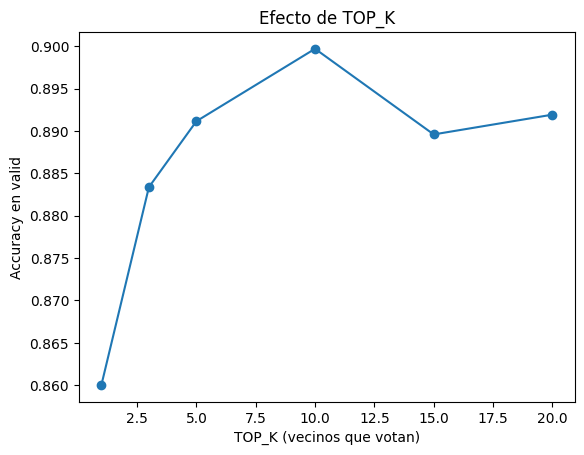

TOP_K elegido: 10


In [11]:
import matplotlib.pyplot as plt
# Accuracy de la raza predicha en valid según la cantidad de vecinos que votan
valores_k = [1, 3, 5, 10, 15, 20]
acc_k = pd.Series({k: evaluar("valid", k_voto=k)["acierto"].mean() for k in valores_k}, name="accuracy valid")
display(acc_k.round(3).to_frame())
plt.plot(acc_k.index, acc_k.values, marker="o")
plt.xlabel("TOP_K (vecinos que votan)"); plt.ylabel("Accuracy en valid"); plt.title("Efecto de TOP_K"); plt.show()

K_VOTO = int(acc_k.idxmax())
print("TOP_K elegido:", K_VOTO)

**Resultado.** Con 1 solo vecino la accuracy en `valid` es 86,0%: la predicción depende de una
única imagen y un vecino equivocado basta para fallar. Al aumentar los vecinos que votan sube hasta
**90,0% con TOP_K = 10** y luego baja levemente (89,0–89,2% con 15 y 20), porque empiezan a votar
imágenes menos parecidas. Se elige **TOP_K = 10**, que además coincide con la cantidad de vecinos
que muestra la app y con el k del NDCG@10.

### 5.4 Calibración del umbral (`SIMILARITY_THRESHOLD`)
Si el score de la raza ganadora (similitud media de los vecinos que la votaron) es bajo, la imagen
no se parece lo suficiente a ninguna raza y se responde `"unknown"`. El umbral se calibra en
**`valid`**: se toma el **percentil 5 del score de las predicciones correctas**, es decir, se
acepta rechazar como máximo el 5% de los aciertos. Después se mide qué pasa en `test`, en el
conjunto independiente y en las imágenes sin perro (que idealmente deberían rechazarse).

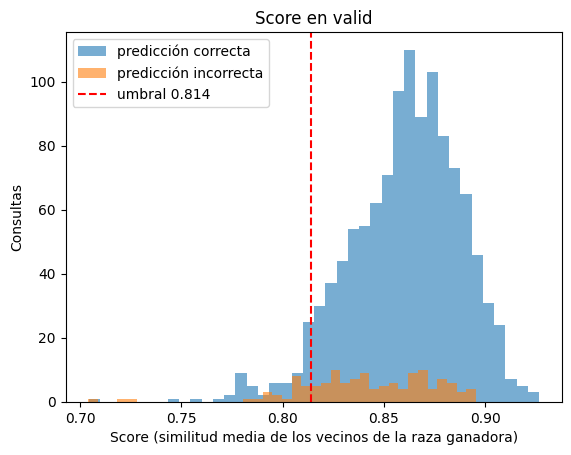

,conjunto,n,% unknown,accuracy (todas),accuracy (no rechazadas)
0,valid,1286,0.064,0.855,0.913
1,test,1287,0.077,0.831,0.901
2,independiente,162,0.562,0.364,0.831
3,sin_perro,19,1.000,NaN,NaN


Umbral calibrado (cosine): 0.814


In [12]:
r_val = evaluar("valid", k_voto=K_VOTO)
plt.hist(r_val.loc[r_val["acierto"], "score"], bins=40, alpha=0.6, label="predicción correcta")
plt.hist(r_val.loc[~r_val["acierto"], "score"], bins=40, alpha=0.6, label="predicción incorrecta")
UMBRAL = float(np.percentile(r_val.loc[r_val["acierto"], "score"], 5))
plt.axvline(UMBRAL, color="red", ls="--", label=f"umbral {UMBRAL:.3f}")
plt.xlabel("Score (similitud media de los vecinos de la raza ganadora)"); plt.ylabel("Consultas")
plt.legend(); plt.title("Score en valid"); plt.show()

filas = []
for nombre in ["valid", "test", "independiente", "sin_perro"]:
    r = evaluar(nombre, k_voto=K_VOTO, umbral=UMBRAL)
    rechazadas = r["pred"] == "unknown"
    filas.append({"conjunto": nombre, "n": len(r), "% unknown": rechazadas.mean(),
                  "accuracy (todas)": r["acierto"].mean() if nombre != "sin_perro" else None,
                  "accuracy (no rechazadas)": r.loc[~rechazadas, "acierto"].mean() if nombre != "sin_perro" else None})
display(pd.DataFrame(filas).round(3))
print(f"Umbral calibrado (cosine): {UMBRAL:.3f}")

**Resultado.** Con el umbral calibrado en `valid` (0,814, percentil 5 de las predicciones
correctas) se rechazan el 100% de las imágenes sin perro, pero también el 56% de las fotos reales
de perros del conjunto independiente: el cambio de dominio baja la similitud con la galería y
muchas fotos válidas quedan debajo del umbral. Además, el histograma muestra que las predicciones
incorrectas tienen scores casi tan altos como las correctas: el score no distingue errores entre
razas, sino imágenes muy distintas a la galería.

### Umbrales alternativos
Se comparan las distribuciones del score en `valid`, en fotos reales de perros (independiente) y
en imágenes sin perro, y se evalúan umbrales más permisivos. Todos los candidatos se calculan
**solo sobre `valid`** (percentiles 5, 2, 1 y 0,5 del score de las predicciones correctas); los
demás conjuntos únicamente muestran la consecuencia de cada elección.

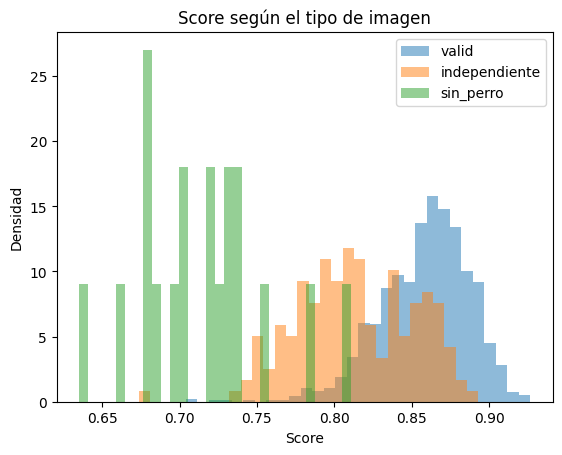

{'valid': (0.704, 0.862, 0.927), 'independiente': (0.674, 0.811, 0.893), 'sin_perro': (0.635, 0.718, 0.811)} (mín, mediana, máx)


,percentil (valid),umbral,% unknown valid,% unknown test,% unknown independiente,% unknown sin_perro
0,5.0,0.814,0.064,0.077,0.562,1.000
1,2.0,0.795,0.025,0.024,0.346,0.947
2,1.0,0.780,0.012,0.010,0.198,0.895
3,0.5,0.777,0.007,0.009,0.173,0.895


Umbral elegido: 0.78


In [14]:
# Distribución del score en los tres grupos (sin umbral)
scores = {n: evaluar(n, k_voto=K_VOTO)["score"] for n in ["valid", "independiente", "sin_perro"]}
for n, s in scores.items():
    plt.hist(s, bins=30, alpha=0.5, density=True, label=n)
plt.xlabel("Score"); plt.ylabel("Densidad"); plt.legend(); plt.title("Score según el tipo de imagen"); plt.show()
print({n: (round(s.min(), 3), round(s.median(), 3), round(s.max(), 3)) for n, s in scores.items()}, "(mín, mediana, máx)")

# Umbrales candidatos, todos calculados sobre las predicciones correctas de valid
correctas = r_val.loc[r_val["acierto"], "score"]
filas = []
for p in [5, 2, 1, 0.5]:
    u = float(np.percentile(correctas, p))
    fila = {"percentil (valid)": p, "umbral": round(u, 3)}
    for n in ["valid", "test", "independiente", "sin_perro"]:
        fila[f"% unknown {n}"] = round((evaluar(n, k_voto=K_VOTO, umbral=u)["pred"] == "unknown").mean(), 3)
    filas.append(fila)
display(pd.DataFrame(filas))
UMBRAL = round(float(np.percentile(correctas, 1)), 2)
print("Umbral elegido:", UMBRAL)

**Resultado.**
- Los scores se ordenan según qué tan parecida es la imagen a la galería: **sin perro** (mediana
  0,718) < **fotos reales de perros** (mediana 0,811) < **valid** (mediana 0,862). El umbral del
  percentil 5 (0,814) cae en el medio de las fotos reales, y por eso rechaza a más de la mitad.
- **Umbral elegido: percentil 1 de `valid`, `SIMILARITY_THRESHOLD = 0.78`.** Rechaza el 89,5% de
  las imágenes sin perro (17 de 19) y solo el 19,8% de las fotos reales de perros (frente al 56%
  del percentil 5), con un impacto mínimo en `test` (1%). Un umbral más permisivo (percentil 0,5)
  prácticamente no cambia los resultados; uno más estricto vuelve a rechazar muchas fotos reales.
- **Limitación:** el valor del umbral se calcula solo con `valid`, pero la elección entre los
  candidatos se apoyó en su efecto sobre el conjunto independiente y las imágenes sin perro, lo que
  implica una influencia leve del conjunto de evaluación en la decisión. Además, el score **no
  detecta errores entre razas** (las predicciones incorrectas de `valid` tienen scores similares a
  las correctas): solo identifica imágenes muy distintas a la galería.

### 5.5 Análisis de fallos
Razas con peor NDCG@10 en `test` y ejemplos de consultas mal clasificadas junto con sus 10 vecinos
más similares, para entender por qué falla la búsqueda.

Razas con peor NDCG@10 en test:


,ndcg,accuracy,n
raza,,,
Labradoodle,0.383,0.375,16
Bulldog,0.416,0.429,21
Lhasa,0.480,0.481,27
Chinese Crested,0.499,0.474,19
American Hairless,0.542,0.667,12
Boston Terrier,0.586,0.786,14
Cockapoo,0.614,0.824,17
Great Dane,0.617,0.762,21


raza               pred          
Lhasa              Shih-Tzu          10
Bulldog            Boston Terrier     8
Labradoodle        Cockapoo           4
Lhasa              Maltese            4
American Hairless  Mex Hairless       4
Bearded Collie     Lhasa              3
Malinois           Groenendael        3
Shih-Tzu           Lhasa              3
dtype: int64


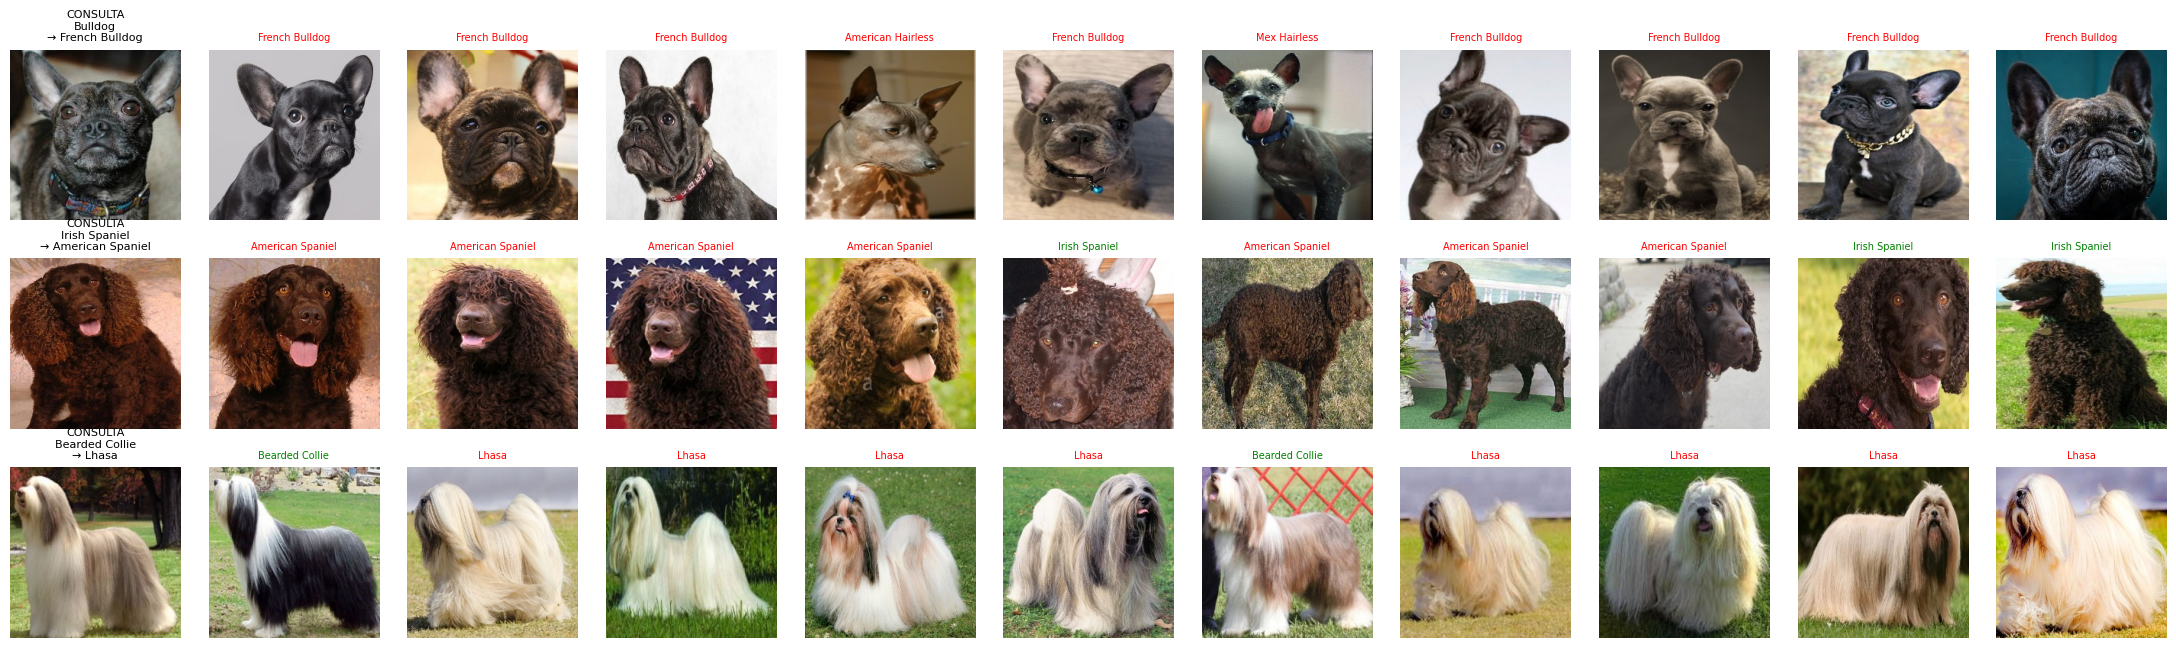

In [15]:
from PIL import Image

r_test = evaluar("test", k_voto=K_VOTO, umbral=UMBRAL)
por_raza = r_test.groupby("raza").agg(ndcg=("ndcg@10", "mean"), accuracy=("acierto", "mean"), n=("raza", "size"))
print("Razas con peor NDCG@10 en test:")
display(por_raza.sort_values("ndcg").head(8).round(3))

# Confusiones más frecuentes (raza real → raza predicha)
errores = r_test[~r_test["acierto"] & (r_test["pred"] != "unknown")]
print(errores.groupby(["raza", "pred"]).size().sort_values(ascending=False).head(8))

# 3 consultas fallidas con su top-10 (verde = misma raza, rojo = otra)
galeria = conjuntos["train"]
fig, ejes = plt.subplots(3, 11, figsize=(22, 6.5))
for fila_ejes, (i, f) in zip(ejes, errores.sample(3, random_state=1).iterrows()):
    fila_ejes[0].imshow(Image.open(conjuntos["test"].at[i, "ruta"]).convert("RGB"))
    fila_ejes[0].set_title(f"CONSULTA\n{f['raza']}\n→ {f['pred']}", fontsize=8)
    for eje, j in zip(fila_ejes[1:], f["top10"]):
        eje.imshow(Image.open(galeria.at[j, "ruta"]).convert("RGB"))
        eje.set_title(galeria.at[j, "raza"], fontsize=7,
                      color="green" if galeria.at[j, "raza"] == f["raza"] else "red")
    for eje in fila_ejes: eje.axis("off")
plt.tight_layout(); plt.show()

**Resultado.**
- Las razas con peor NDCG@10 en `test` son **Labradoodle (0,38), Bulldog (0,42), Lhasa (0,48),
  Chinese Crested (0,50) y American Hairless (0,54)**.
- Las confusiones más frecuentes coinciden con los pares anticipados en el EDA (sección 6.2 de la
  notebook 1): **Lhasa → Shih-Tzu (10)**, **Bulldog → Boston Terrier (8)**, Labradoodle → Cockapoo
  (4), Lhasa → Maltese (4), American Hairless → Mex Hairless (4) y Malinois → Groenendael (3).
- En los ejemplos visuales:
  - **Bulldog → French Bulldog:** la consulta etiquetada "Bulldog" es, a la vista, un Bulldog
    Francés, y sus 10 vecinos son Bulldogs Franceses. El error es del **etiquetado del dataset**
    (ruido ya observado en la carpeta "Bulldog"), no del buscador.
  - **Irish Spaniel → American Spaniel:** los vecinos de ambas razas son perros marrones de pelo
    rizado prácticamente indistinguibles. Es consistente con lo hallado en el control de calidad,
    donde la misma foto aparecía en las dos carpetas.
  - **Bearded Collie → Lhasa:** perros de pelo largo, lacio y claro; con fondo y pose similares,
    los embeddings de ImageNet los agrupan juntos.
- **Conclusión:** buena parte de los errores se explica por razas muy parecidas y por ruido de
  etiquetas del dataset. Un embedding entrenado específicamente para distinguir razas (Etapa 2)
  debería separar mejor algunos de estos pares.

## 6. Modelo A (obligatorio): fine-tuning de ResNet

`train_classifier` debe guardar el checkpoint en `models/resnet18_finetuned.pth`
(o el nombre configurado en `RESNET18_MODEL_NAME`). Documentar la estrategia de fine-tuning
y los hiperparámetros utilizados (learning rate, batch size, epochs, optimizador, scheduler,
regularización).

In [ ]:
from lib.bootstrap import build_classifier

classifier = build_classifier(settings)
classifier.set_active_model("resnet18_finetuned")
classifier.train_classifier()

In [ ]:
metrics_a = classifier.evaluate_classifier()
metrics_a

### Curvas de entrenamiento y matriz de confusión (Modelo A)

TO-DO: graficar las curvas de entrenamiento/validación (loss y accuracy) y la matriz de confusión
normalizada, con los pares de razas más confundidos.

In [ ]:
## TO-DO: curvas de entrenamiento y matriz de confusión del Modelo A.

## 7. Modelo B (obligatorio): CNN propia

`train_classifier` con el modelo activo `cnn_custom` debe guardar el checkpoint en
`models/cnn_custom.pth` (o el nombre configurado en `CNN_CUSTOM_MODEL_NAME`).
Definí la arquitectura en un módulo importable (por ejemplo, `src/lib/models/cnn_custom.py`):
si la clase vive en la notebook, `torch.load` falla en la app.

TO-DO: documentar la arquitectura (capas, parámetros, dimensión del embedding), los
hiperparámetros y la tabla de experimentos.

In [ ]:
classifier.set_active_model("cnn_custom")
classifier.train_classifier()

In [ ]:
metrics_b = classifier.evaluate_classifier()
metrics_b

### Curvas de entrenamiento y matriz de confusión (Modelo B)

In [ ]:
## TO-DO: curvas de entrenamiento y matriz de confusión del Modelo B.

## 8. Evaluación sobre el conjunto independiente

TO-DO: las mismas métricas sobre el conjunto independiente para ambos modelos. Comparar con `test`
y discutir el cambio de dominio.

In [ ]:
## TO-DO: métricas de ambos modelos sobre el conjunto independiente.

## 9. Embeddings de los modelos entrenados

TO-DO:
- NDCG@10 de la Etapa 1 con los embeddings del baseline, del Modelo A y del Modelo B
  (`classifier.extract_custom_embedding`), con la misma galería y las mismas consultas.
- Visualización PCA o t-SNE de los embeddings de `test` de cada modelo, lado a lado y coloreada
  por raza (con un subconjunto de razas).

In [ ]:
## TO-DO: NDCG@10 por modelo de embeddings y visualización PCA / t-SNE.

## 10. Análisis de errores

TO-DO: ejemplos de falsos positivos y falsos negativos con la imagen y su score, razas con peor
desempeño e hipótesis sobre las causas.

In [ ]:
## TO-DO: análisis de errores con ejemplos visuales.

## 11. Costo computacional

TO-DO: cantidad de parámetros, tamaño en MB, tiempo de inferencia por imagen en CPU y dimensión
del embedding de cada modelo.

In [ ]:
## TO-DO: costo computacional de cada modelo.

## 12. Comparación y elección final

TO-DO:
- Tabla comparativa de todas las métricas (Modelo A, Modelo B y baseline en la Etapa 1).
- Qué modelo usa la app para clasificar (Etapas 2 y 3) y qué embeddings para la búsqueda
  (`EMBEDDING_MODEL`), con su justificación.
- Búsqueda por similitud vs. clasificación supervisada: ventajas, limitaciones y cuándo conviene cada una.
- Trade-offs entre precisión, velocidad de inferencia, memoria y complejidad.

In [ ]:
## TO-DO: tabla comparativa final.

## 13. Descargar los checkpoints

Descargalos y colocalos en `models/` de tu entorno local para que la aplicación los use.
Recordá publicarlos en un link público de solo lectura y ponerlo en el README y en el PR.

In [ ]:
!ls -lh models/

try:
    from google.colab import files

    files.download(str(settings.model_path / settings.resnet18_model_name))
    files.download(str(settings.model_path / settings.cnn_custom_model_name))
except ImportError:
    print("Fuera de Colab: los checkpoints quedan en models/")